In [1]:
# Autoreload all modules so that changes in the code are reflected without needing to restart the kernel
%load_ext autoreload
%autoreload 2

# Event-Aligned LFP Time Traces

Compare two explicitly labeled event/condition selections using mean power, coherence, or Granger across time. Events are averaged within each recording, selected frequency bins are averaged, then recordings are weighted equally. Shading shows **mean & SEM across recording averages**, not across pooled trials.

Use the stored spectral scale: Each point retains the collection's spectral timestep; a smooth-looking line does not imply finer temporal resolution.

## Imports

In [2]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Works when Jupyter starts in the repository root or a notebook subdirectory.
REPO_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "src" / "coop_ephys_analysis").is_dir()),
    None,
)
if REPO_ROOT is None:
    raise FileNotFoundError("Start Jupyter inside coop_ephys_analysis or set REPO_ROOT explicitly.")
for path in (REPO_ROOT, REPO_ROOT / "src"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

from coop_ephys_analysis.behavior import load_pickle
from coop_ephys_analysis.lfp import (
    build_condition_dict,
    load_lfp_collection,
    plot_event_average_traces,
    update_collection_events_from_behavior,
)

## Load the Saved LFP Collection

Set the day and data root once. Collection and behavior paths below use the same day. Loading the collection requires its accompanying recordings directory and can use substantial memory.

In [3]:
DAY = 8
LFP_DATA_ROOT = Path(r"D:\PadillaCoreanoLab\Coop_Ephys")
collection_path = LFP_DATA_ROOT / f"D{DAY}_lfp_collection" / "lfp_collection.json"
behavior_path = REPO_ROOT / "data" / "processed" / "stage4_thresholded" / f"Stage4_D{DAY}.pkl"

for path in (collection_path, behavior_path):
    if not path.is_file():
        raise FileNotFoundError(path)

collection = load_lfp_collection(collection_path)
print(f"Loaded Day {DAY}: {len(collection.recordings)} LFP recordings")
print("Spectral timesteps (s):", sorted({rec.timestep for rec in collection.recordings}))

Loaded Day 8: 10 LFP recordings
Spectral timesteps (s): [0.5]


## Load Saved Behavioral Events Into the LFP Collection

Import the processed behavior pickle saved by `stage4_quality_control.ipynb`. The helper matches behavior recording names to `.rec` names, converts seconds to milliseconds, and updates recording- and collection-level event dictionaries.

The saved filtered nosepokes, including forced-trial removal if that step was saved, are used exactly as stored. This notebook does not rerun matching or remove another batch. Baseline ITI events are imported with the other events but are not used for normalization.

In [4]:
processed_behaviors = load_pickle(behavior_path)
print(f"Loaded {len(processed_behaviors)} behavior recordings from {behavior_path}")

event_update_summary = update_collection_events_from_behavior(
    collection,
    processed_behaviors,
    source_unit="seconds",
    strict=True,
)
print("Updated recordings:", len(event_update_summary["updated_recordings"]))
print("Unused behavior recordings:", event_update_summary["unused_behavior_recordings"])
event_update_summary["imported_events"]

Loaded 10 behavior recordings from c:\Users\zhaoz\Desktop\Research\Cooperation\coop_ephys_analysis\data\processed\stage4_thresholded\Stage4_D8.pkl
Updated recordings: 10
Unused behavior recordings: []


{'20250517_105306_Stage4_D8_1-2_merged.rec': ['baseline iti 2s',
  'coop light',
  'coop nose poke',
  'filtered coop nose poke',
  'filtered selfish nose poke',
  'recipient port entry',
  'selfish light',
  'selfish nose poke',
  'subject port entry'],
 '20250517_105306_Stage4_D8_1-3_merged.rec': ['baseline iti 2s',
  'coop light',
  'coop nose poke',
  'filtered coop nose poke',
  'filtered selfish nose poke',
  'recipient port entry',
  'selfish light',
  'selfish nose poke',
  'subject port entry'],
 '20250517_105306_Stage4_D8_2-1_merged.rec': ['baseline iti 2s',
  'coop light',
  'coop nose poke',
  'filtered coop nose poke',
  'filtered selfish nose poke',
  'recipient port entry',
  'selfish light',
  'selfish nose poke',
  'subject port entry'],
 '20250517_105306_Stage4_D8_2-4_merged.rec': ['baseline iti 2s',
  'coop light',
  'coop nose poke',
  'filtered coop nose poke',
  'filtered selfish nose poke',
  'recipient port entry',
  'selfish light',
  'selfish nose poke',
  'su

In [5]:
# Inspect imported event counts before choosing comparisons.
SELFISH_EVENT = "filtered selfish nose poke"
COOP_EVENT = "filtered coop nose poke"
event_counts = pd.DataFrame([
    {
        "recording": rec.name,
        **{event: len(rec.event_dict.get(event, []))
           for event in (SELFISH_EVENT, COOP_EVENT, "baseline iti 2s")},
    }
    for rec in collection.recordings
])
display(event_counts)

for event in (SELFISH_EVENT, COOP_EVENT):
    if not any(len(rec.event_dict.get(event, [])) for rec in collection.recordings):
        raise ValueError(f"No saved {event!r} events were imported. Check the behavior QC output.")

,recording,filtered selfish nose poke,filtered coop nose poke,baseline iti 2s
0,20250517_105306_Stage4_D8_1-2_merged.rec,25,166,193
1,20250517_105306_Stage4_D8_1-3_merged.rec,25,166,193
2,20250517_105306_Stage4_D8_2-1_merged.rec,10,199,157
3,20250517_105306_Stage4_D8_2-4_merged.rec,10,199,157
4,20250517_121746_Stage4_D8_6-1_merged.rec,208,40,223
5,20250517_121746_Stage4_D8_6-3_merged.rec,81,103,295
6,20250517_134054_Stage4_D8_4-1_merged.rec,34,126,338
7,20250517_134054_Stage4_D8_4-2_merged.rec,2,149,200
8,20250517_134054_Stage4_D8_4-3_merged.rec,34,126,338
9,20250517_134054_Stage4_D8_4-4_merged.rec,2,149,200


## Recording Conditions

In [6]:
condition_dict = build_condition_dict(collection)
for condition, recording_names in condition_dict.items():
    print(f"{condition}: {len(recording_names)} recordings")
    for name in recording_names:
        print("  ", name)

subject with recipient: 4 recordings
   20250517_105306_Stage4_D8_1-2_merged.rec
   20250517_105306_Stage4_D8_2-4_merged.rec
   20250517_134054_Stage4_D8_4-3_merged.rec
   20250517_134054_Stage4_D8_4-4_merged.rec
recipient: 4 recordings
   20250517_105306_Stage4_D8_1-3_merged.rec
   20250517_105306_Stage4_D8_2-1_merged.rec
   20250517_134054_Stage4_D8_4-1_merged.rec
   20250517_134054_Stage4_D8_4-2_merged.rec
subject alone: 2 recordings
   20250517_121746_Stage4_D8_6-1_merged.rec
   20250517_121746_Stage4_D8_6-3_merged.rec


## Shared Plot Settings

The function accepts the same core arguments as `plot_event_average_spectrogram`. `pre_window=3.5`, `event_len=3.5`, and `post_window=0` request a fixed window from ?3.5 to +3.5 seconds relative to onset; sampled points stop before the upper endpoint. With `event_len=None`, actual event durations are used and contributing counts may decrease toward the end.

Power uses `regions`; coherence and Granger use `pairs`. **Granger follows the existing spectrogram convention: `(target, source)`**, so `("mPFC", "BLA")` means BLA ? mPFC. `max_traces` limits panels, not the two comparison lines.

A list passed as `selected_condition` pools those conditions into one line. Use `comparison_condition` for a separate line. Omitted comparison fields inherit the first line's event or condition. Omit both comparison arguments for a single line.

In [22]:
FREQ_RANGE = (4, 12)  # Hz; e.g. change to (4, 12) for theta
PRE_WINDOW = 3.5
EVENT_LEN = 3.5
POST_WINDOW = 0
REGIONS = None  # None selects all available regions, or use ["mPFC", "BLA"]
COHERENCE_PAIRS = [("mPFC", "BLA"), ("mPFC", "NAc")]
GRANGER_PAIRS = [("mPFC", "BLA"), ("BLA", "mPFC")]  # BLA -> mPFC; mPFC -> BLA

# The metrics must already have been computed and saved.
display(pd.DataFrame([
    {"recording": rec.name, **{mode: hasattr(rec, mode) for mode in ("power", "coherence", "granger")}}
    for rec in collection.recordings
]))
results = {}

,recording,power,coherence,granger
0,20250517_105306_Stage4_D8_1-2_merged.rec,True,True,True
1,20250517_105306_Stage4_D8_1-3_merged.rec,True,True,True
2,20250517_105306_Stage4_D8_2-1_merged.rec,True,True,True
3,20250517_105306_Stage4_D8_2-4_merged.rec,True,True,True
4,20250517_121746_Stage4_D8_6-1_merged.rec,True,True,True
5,20250517_121746_Stage4_D8_6-3_merged.rec,True,True,True
6,20250517_134054_Stage4_D8_4-1_merged.rec,True,True,True
7,20250517_134054_Stage4_D8_4-2_merged.rec,True,True,True
8,20250517_134054_Stage4_D8_4-3_merged.rec,True,True,True
9,20250517_134054_Stage4_D8_4-4_merged.rec,True,True,True


## Power: Selfish vs Cooperative

Compare the two filtered event types within the subject-with-recipient condition. Event counts may differ between lines; each recording still contributes equal weight to its own line.

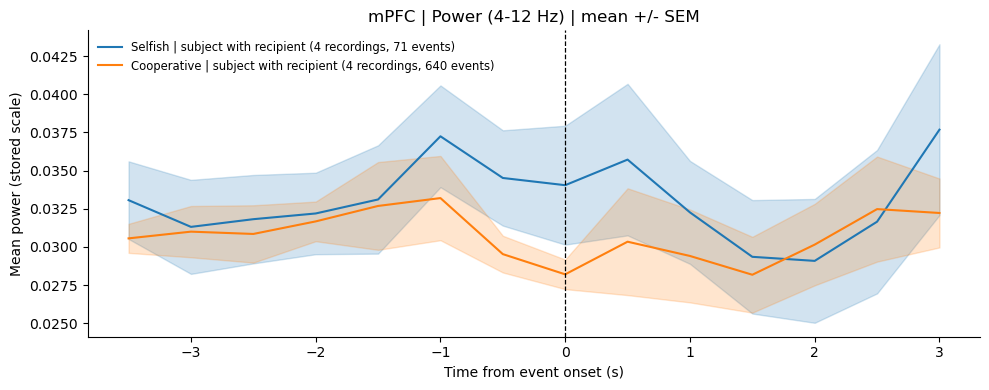

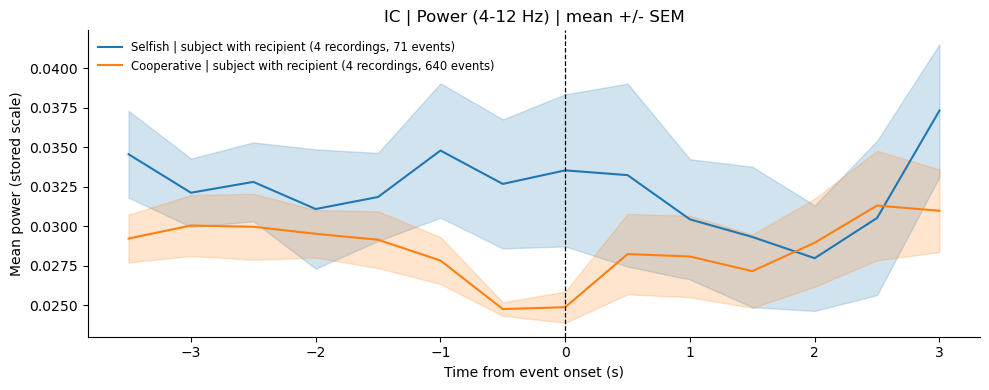

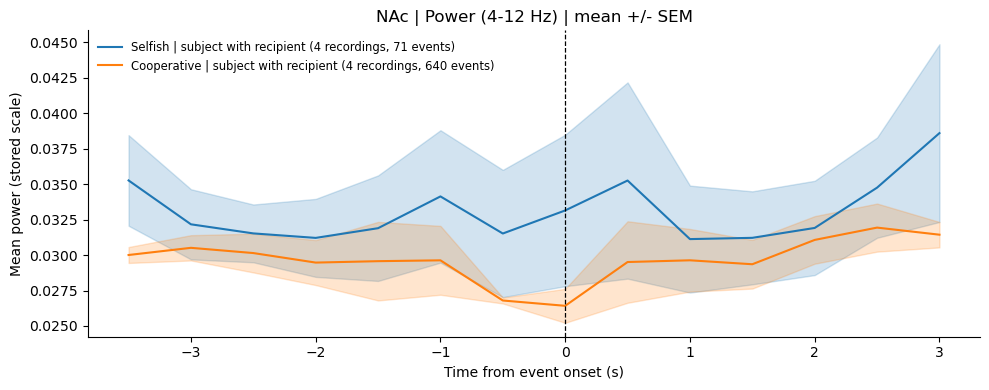

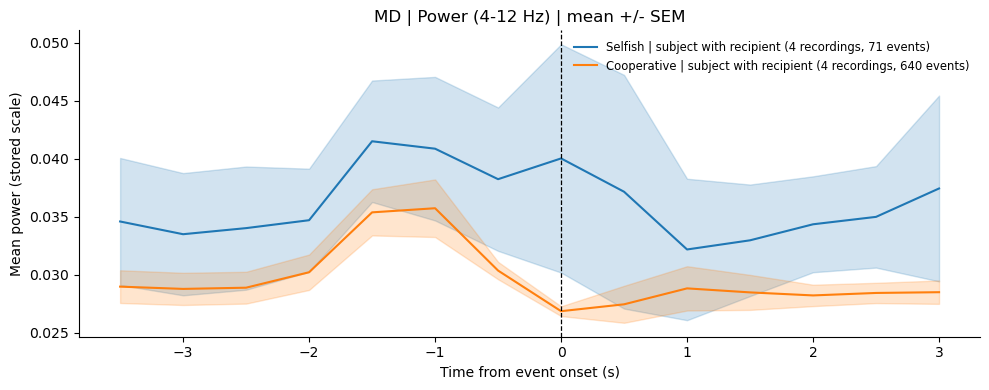

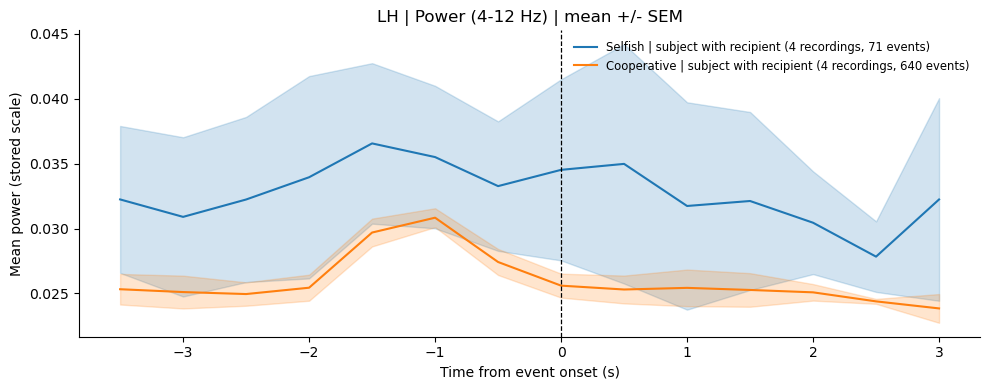

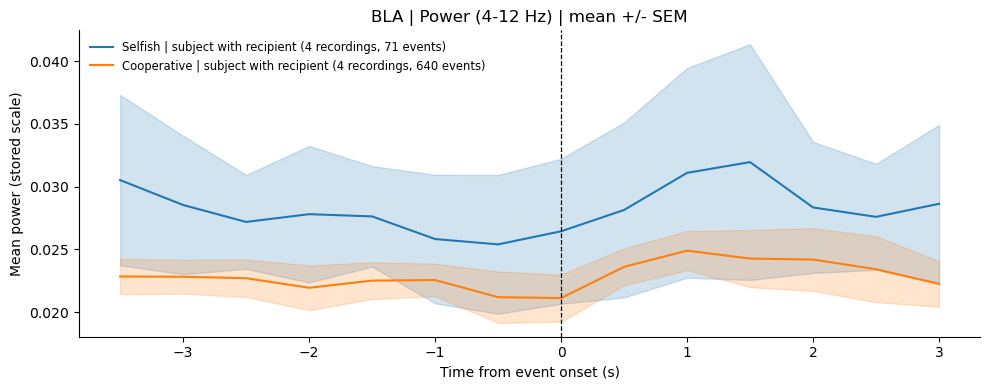

In [23]:
results["power_choice"] = plot_event_average_traces(
    collection,
    event=SELFISH_EVENT,
    condition_recordings=condition_dict,
    selected_condition="subject with recipient",
    mode="power",
    event_len=EVENT_LEN,
    pre_window=PRE_WINDOW,
    post_window=POST_WINDOW,
    freq_range=FREQ_RANGE,
    regions=REGIONS,
    comparison_event=COOP_EVENT,
    labels=("Selfish | subject with recipient", "Cooperative | subject with recipient"),
)
plt.show()

## Power: Subject Alone vs Subject With Recipient

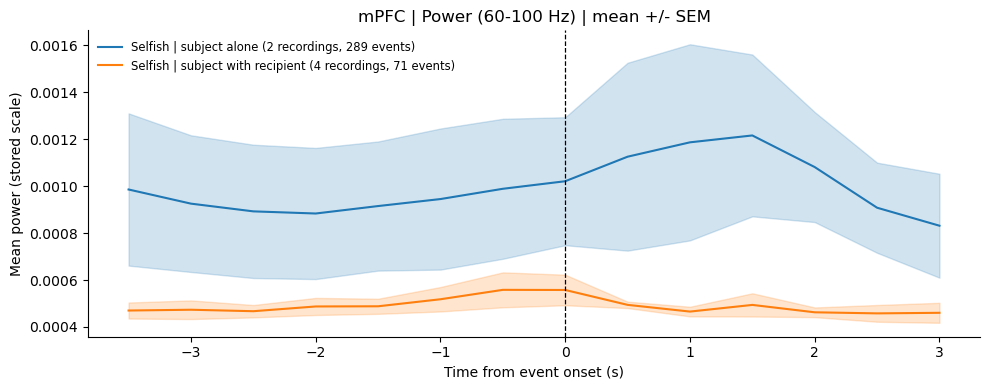

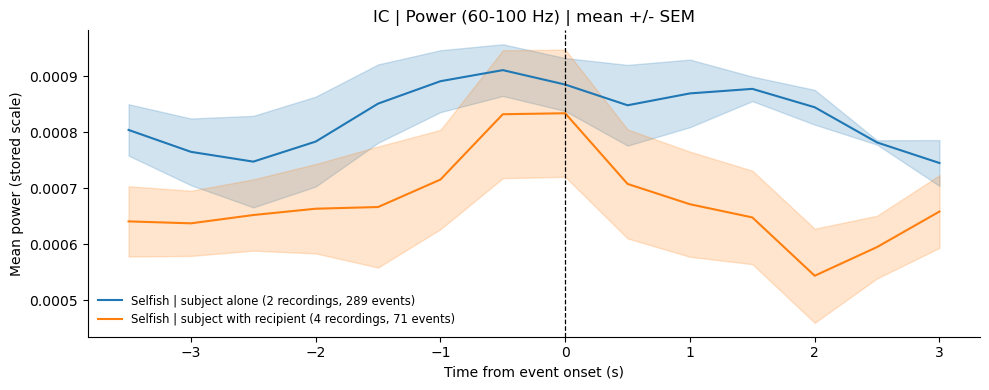

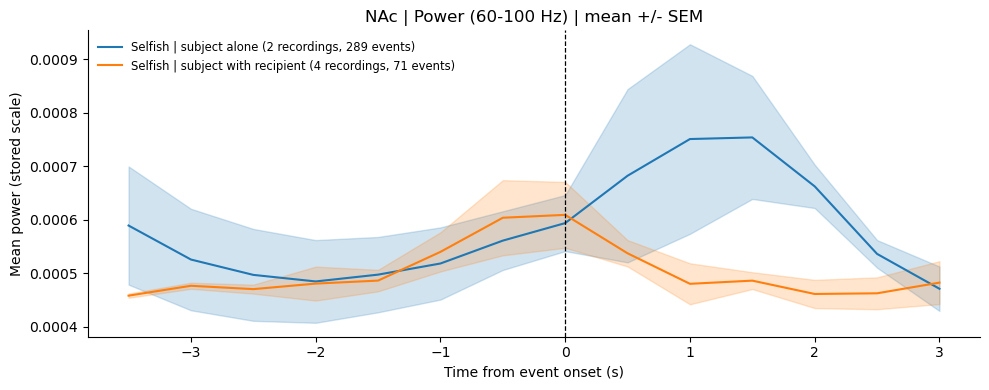

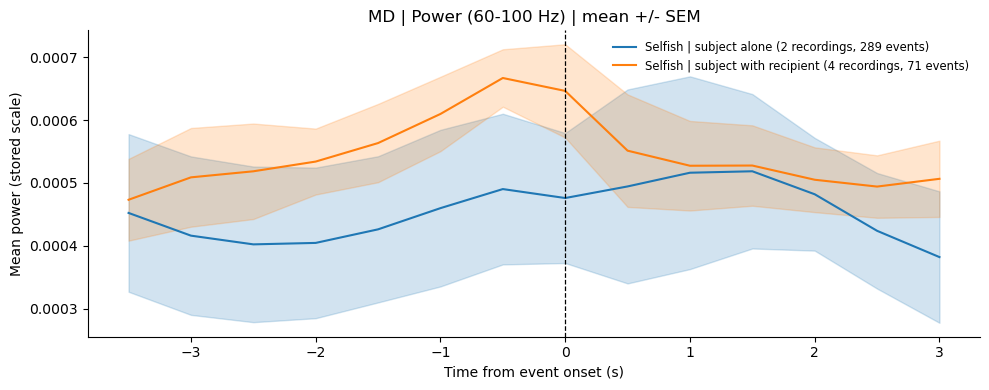

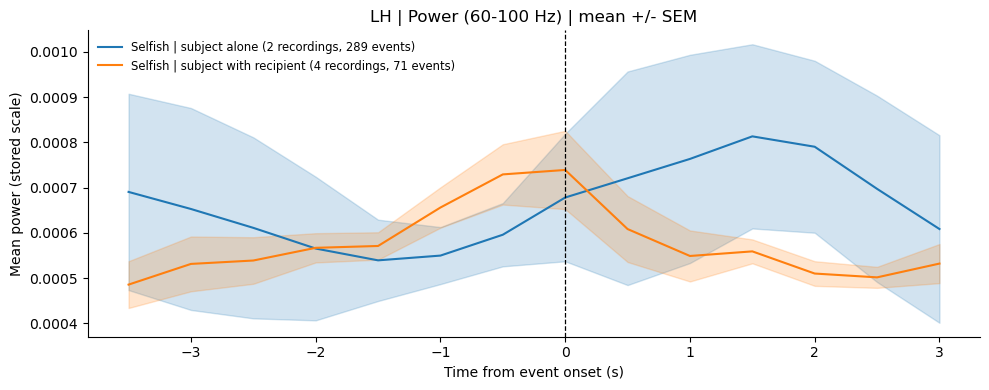

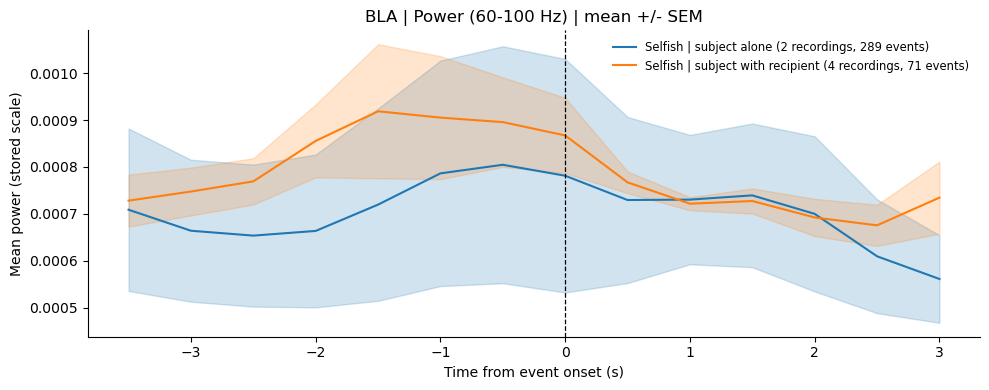

In [9]:
results["power_condition"] = plot_event_average_traces(
    collection,
    event=SELFISH_EVENT,
    condition_recordings=condition_dict,
    selected_condition="subject alone",
    mode="power",
    event_len=EVENT_LEN,
    pre_window=PRE_WINDOW,
    post_window=POST_WINDOW,
    freq_range=FREQ_RANGE,
    regions=REGIONS,
    comparison_condition="subject with recipient",
    labels=("Selfish | subject alone", "Selfish | subject with recipient"),
)
plt.show()

## Coherence: Choice and Condition Comparisons

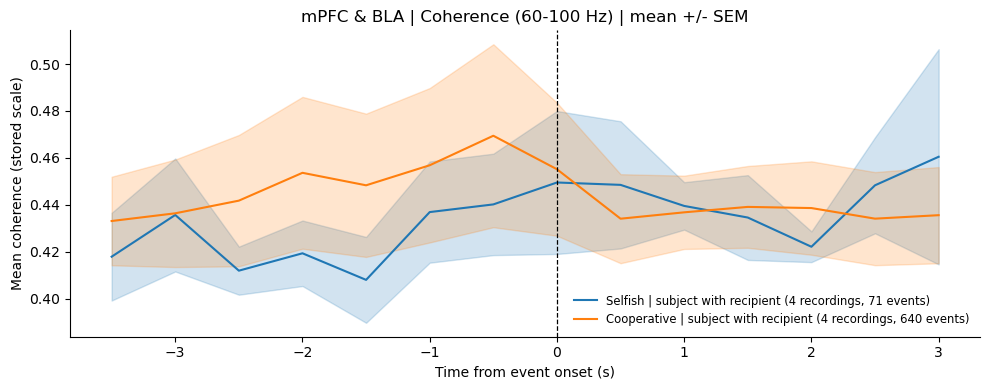

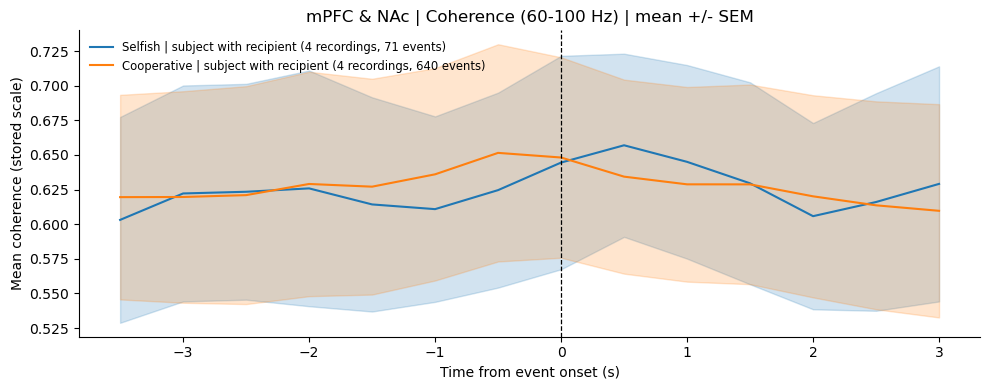

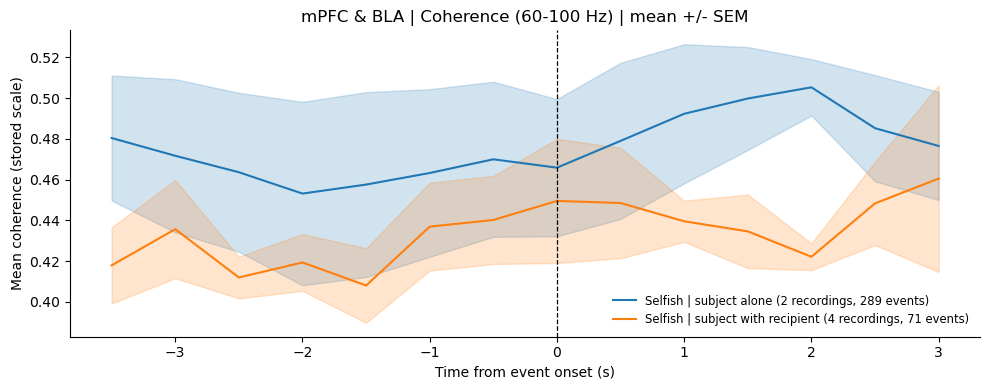

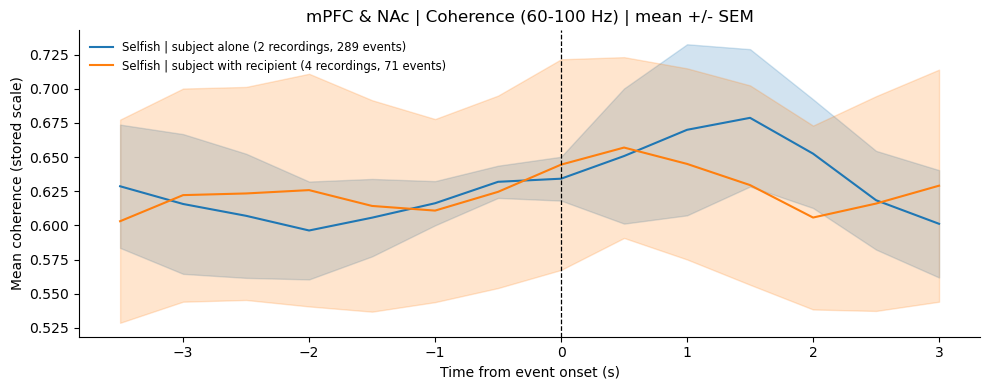

In [10]:
results["coherence_choice"] = plot_event_average_traces(
    collection,
    event=SELFISH_EVENT,
    condition_recordings=condition_dict,
    selected_condition="subject with recipient",
    mode="coherence",
    event_len=EVENT_LEN,
    pre_window=PRE_WINDOW,
    post_window=POST_WINDOW,
    freq_range=FREQ_RANGE,
    pairs=COHERENCE_PAIRS,
    comparison_event=COOP_EVENT,
    labels=("Selfish | subject with recipient", "Cooperative | subject with recipient"),
)
plt.show()

results["coherence_condition"] = plot_event_average_traces(
    collection,
    event=SELFISH_EVENT,
    condition_recordings=condition_dict,
    selected_condition="subject alone",
    mode="coherence",
    event_len=EVENT_LEN,
    pre_window=PRE_WINDOW,
    post_window=POST_WINDOW,
    freq_range=FREQ_RANGE,
    pairs=COHERENCE_PAIRS,
    comparison_condition="subject with recipient",
    labels=("Selfish | subject alone", "Selfish | subject with recipient"),
)
plt.show()

## Granger: Choice and Condition Comparisons

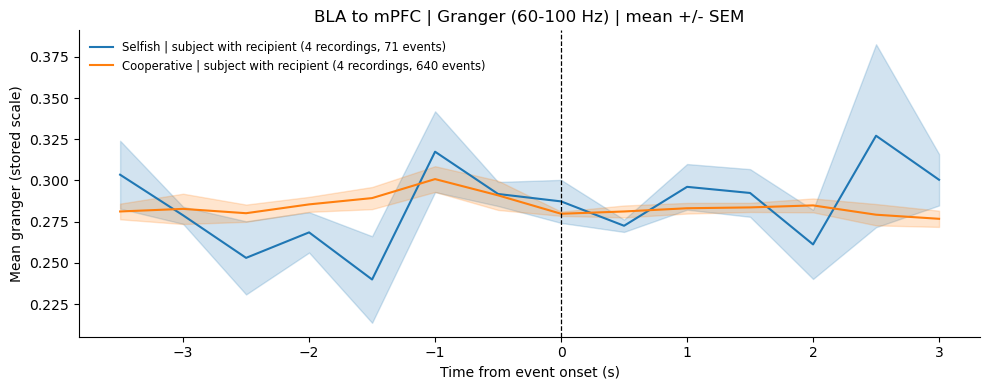

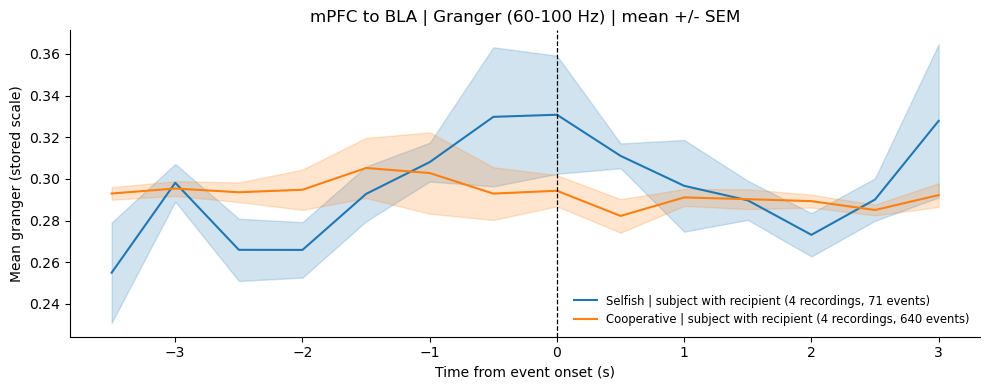

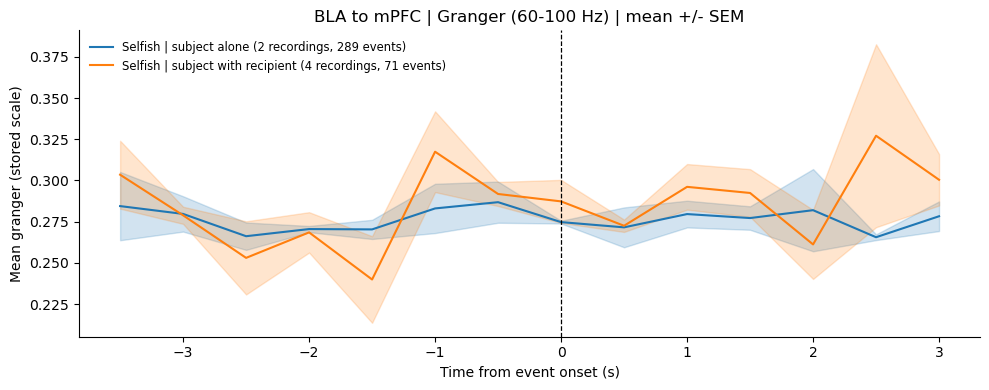

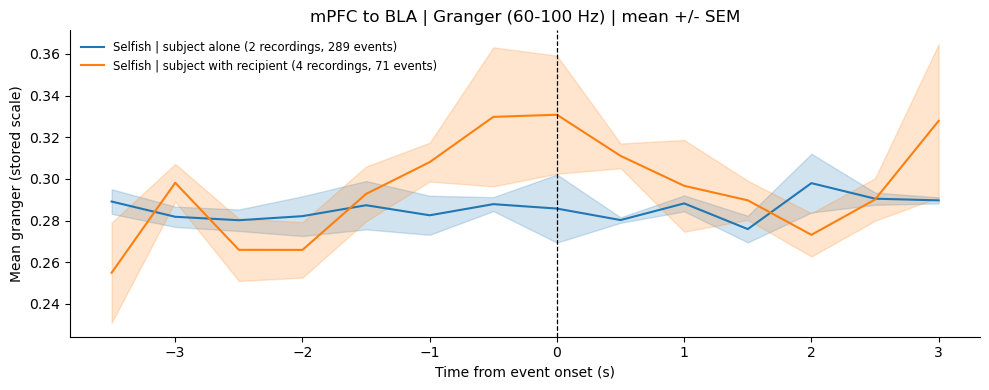

In [11]:
results["granger_choice"] = plot_event_average_traces(
    collection,
    event=SELFISH_EVENT,
    condition_recordings=condition_dict,
    selected_condition="subject with recipient",
    mode="granger",
    event_len=EVENT_LEN,
    pre_window=PRE_WINDOW,
    post_window=POST_WINDOW,
    freq_range=FREQ_RANGE,
    pairs=GRANGER_PAIRS,
    comparison_event=COOP_EVENT,
    labels=("Selfish | subject with recipient", "Cooperative | subject with recipient"),
)
plt.show()

results["granger_condition"] = plot_event_average_traces(
    collection,
    event=SELFISH_EVENT,
    condition_recordings=condition_dict,
    selected_condition="subject alone",
    mode="granger",
    event_len=EVENT_LEN,
    pre_window=PRE_WINDOW,
    post_window=POST_WINDOW,
    freq_range=FREQ_RANGE,
    pairs=GRANGER_PAIRS,
    comparison_condition="subject with recipient",
    labels=("Selfish | subject alone", "Selfish | subject with recipient"),
)
plt.show()

## Inspect Numerical Results and Contributing Counts

Each result contains `lines`, `trace_labels`, and Matplotlib `axes`. Each line stores its time axis, selected frequencies, recording names, valid event counts, skipped-recording reasons, and per-panel `traces`. A trace provides the mean, SEM, individual recording traces, and contributing recording count at each time bin.

Incomplete event windows are excluded using the same rules as the spectrogram helper. NaN values do not contribute to means or SEM. SEM is undefined (NaN, with no shaded band) when fewer than two recordings contribute; a single-recording mean remains visible. Counts are computed separately for each region/pair. These are descriptive comparisons; no significance testing or paired-difference analysis is performed.

In [12]:
summary_rows = []
for comparison, result in results.items():
    for line in result["lines"]:
        if line["skipped_recordings"]:
            print(comparison, line["label"], "skipped:", line["skipped_recordings"])
        for panel, trace in line["traces"].items():
            n = trace["contributing_recordings"]
            summary_rows.append({
                "comparison": comparison,
                "line": line["label"],
                "region_or_pair": panel,
                "valid_events": sum(line["event_counts"].values()),
                "recordings_with_windows": len(line["recording_names"]),
                "min_contributing_recordings": int(n.min()),
                "max_contributing_recordings": int(n.max()),
            })
display(pd.DataFrame(summary_rows))

,comparison,line,region_or_pair,valid_events,recordings_with_windows,min_contributing_recordings,max_contributing_recordings
0,power_choice,Selfish | subject with recipient,mPFC,71,4,4,4
1,power_choice,Selfish | subject with recipient,IC,71,4,4,4
2,power_choice,Selfish | subject with recipient,NAc,71,4,4,4
3,power_choice,Selfish | subject with recipient,MD,71,4,4,4
4,power_choice,Selfish | subject with recipient,LH,71,4,4,4
5,power_choice,Selfish | subject with recipient,BLA,71,4,4,4
6,power_choice,Cooperative | subject with recipient,mPFC,640,4,4,4
7,power_choice,Cooperative | subject with recipient,IC,640,4,4,4
8,power_choice,Cooperative | subject with recipient,NAc,640,4,4,4
9,power_choice,Cooperative | subject with recipient,MD,640,4,4,4


In [13]:
# Example numerical trace table; no files are written automatically.
example_result = results["power_choice"]
example_line = example_result["lines"][0]
example_panel = example_result["trace_labels"][0]
example_trace = example_line["traces"][example_panel]
pd.DataFrame({
    "time_from_onset_s": example_line["relative_time"],
    "mean": example_trace["mean"],
    "sem": example_trace["sem"],
    "n_recordings": example_trace["contributing_recordings"],
})

,time_from_onset_s,mean,sem,n_recordings
0,-3.5,0.000470,0.000034,4
1,-3.0,0.000473,0.000040,4
2,-2.5,0.000467,0.000026,4
3,-2.0,0.000487,0.000036,4
4,-1.5,0.000488,0.000032,4
5,-1.0,0.000518,0.000052,4
6,-0.5,0.000558,0.000074,4
7,0.0,0.000558,0.000065,4
8,0.5,0.000494,0.000014,4
9,1.0,0.000466,0.000021,4
